# 2.5 Centres versus children by subzone (H-a, descriptive)

Does supply follow demand? Hypothesis H-a says subzones with more young children have more
childcare centres. This notebook is the descriptive version: for every HDB subzone with at least
100 children aged 0–6 it plots the number of centres against the number of children on log–log
axes and fits an OLS line, whose slope is the elasticity of supply to demand (1 = proportional).
It also ranks subzones by centres per 1,000 children, the supply-per-child measure that stage 3
builds on. The formal tests (Moran's I on supply per child, the supply-pressure index and its LISA)
are in `3_Hypothesis_Testing`.

Original author: Minh (the H-a section of `scripts/make_deck_figures.py`). Converted 2026-11-10;
the other figures of that script belong to stage 3 and are not reproduced here.

**Inputs**
- `output/subzone_pressure.csv` (per subzone: `has_hdb`, `children_0_6`, `centres_n`, `pressure_base`, ...; `scripts/pressure_index.py` / stage 3)
- `output/subzone_stats.csv` (per subzone: `centres_per_1000_children_0_6`, `pct_1to3room`, `child_density_0_6_km2`; stage 1)

**Outputs**
- `figures/ha_centres_vs_children.png` (deck, H-a slide)

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "bt4015").is_dir())
sys.path.insert(0, str(ROOT / "src"))
from bt4015.paths import DATA, OUT, FIG, LARGE

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

# Fixed figure palette (docs/notebook_style.md): categorical order blue, orange, aqua, yellow;
# sequential = single-hue Blues; text in dark grey, never in a series colour.
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, INK2, GRID, SURF = "#333333", "#52514e", "#e6e5e1", "#ffffff"
plt.rcParams.update({"text.color": INK, "axes.labelcolor": INK2, "xtick.color": INK2,
                     "ytick.color": INK2, "axes.edgecolor": GRID, "figure.facecolor": SURF,
                     "savefig.facecolor": SURF, "font.size": 9})

INK3 = "#8a8984"
MIN_CHILDREN = 100          # subzones with fewer children 0-6 are too small to carry a ratio (decisions.md 2026-11-02)
LABELLED = ["TAMPINES NORTH", "PLANTATION", "GARDEN", "BRICKWORKS", "YISHUN EAST"]   # named on the plot

## 1. Load the subzone tables and select the analysis set

`subzone_pressure.csv` carries the children 0–6 and centre counts per subzone; `subzone_stats.csv`
adds centres per 1,000 children and the flat-type mix. The analysis set is HDB subzones with at
least 100 children 0–6 and a defined pressure value, the same 140 subzones used by the LISA in
stage 3, so the numbers are comparable.

In [2]:
# 1. Per-subzone tables.
pressure = pd.read_csv(OUT / "subzone_pressure.csv")
stats = pd.read_csv(OUT / "subzone_stats.csv")[["SUBZONE_C", "pct_1to3room", "child_density_0_6_km2", "centres_per_1000_children_0_6"]]
print(f"subzones: {len(pressure)} in pressure table, {pressure['has_hdb'].sum()} with HDB blocks")

# 2. Analysis set: HDB subzones with >= 100 children 0-6 and a pressure value.
subzones = (pressure[pressure["has_hdb"] & (pressure["children_0_6"] >= MIN_CHILDREN) & pressure["pressure_base"].notna()]
            .merge(stats, on="SUBZONE_C", validate="one_to_one").reset_index(drop=True))
print(f"analysis set: {len(subzones)} subzones, {subzones['children_0_6'].sum():,.0f} children 0-6, "
      f"{subzones['centres_n'].sum():,} centres")
print(f"subzones with zero centres: {(subzones['centres_n'] == 0).sum()}")
print(subzones[["children_0_6", "centres_n"]].describe().round(1).to_string())

subzones: 332 in pressure table, 159 with HDB blocks
analysis set: 140 subzones, 175,437 children 0-6, 1,446 centres
subzones with zero centres: 0
       children_0_6  centres_n
count         140.0      140.0
mean         1253.1       10.3
std          1225.7        7.9
min           103.9        1.0
25%           501.3        5.0
50%           891.8        9.0
75%          1597.2       14.0
max          6838.4       55.0


## 2. Log–log OLS: elasticity of centres to children

log(centres) on log(children). Zero-centre subzones are clipped to one centre before the log
(as in the script) so they stay in the fit. A slope of 1 would mean supply proportional to demand;
the dashed reference line in the plot passes through the means with slope 1.

In [3]:
# 1. Fit (statsmodels, as in the script; pandas keeps the data).
x = np.log(subzones["children_0_6"])
y = np.log(subzones["centres_n"].clip(lower=1))
ols = sm.OLS(y, sm.add_constant(x)).fit()
slope, slope_se = ols.params.iloc[1], ols.bse.iloc[1]

# 2. Numbers for the report; the t-test against slope = 1 says whether supply lags demand.
t_vs_1 = (slope - 1) / slope_se
print(f"n = {len(subzones)}")
print(f"log-log slope = {slope:.3f} (SE {slope_se:.3f}), intercept = {ols.params.iloc[0]:.3f}")
print(f"R2 = {ols.rsquared:.3f}; p(slope = 0) = {ols.pvalues.iloc[1]:.2e}")
print(f"t vs slope 1 = {t_vs_1:.2f}: {'slope below 1 (supply grows slower than demand)' if t_vs_1 < -2 else 'not distinguishable from proportional'}")

n = 140
log-log slope = 0.653 (SE 0.048), intercept = -2.335
R2 = 0.568; p(slope = 0) = 6.69e-27
t vs slope 1 = -7.16: slope below 1 (supply grows slower than demand)


## 3. Spearman: children versus centres per 1,000 children

If the elasticity is below one, bigger subzones should have *fewer* centres per child. The rank
correlation between children 0–6 and centres per 1,000 children checks that directly.

In [4]:
# 1. Centres per 1,000 children 0-6, recomputed here and checked against the stage 1 column.
subzones["centres_per_1000"] = subzones["centres_n"] / subzones["children_0_6"] * 1000
print(f"max |recomputed - subzone_stats.centres_per_1000_children_0_6| = "
      f"{(subzones['centres_per_1000'] - subzones['centres_per_1000_children_0_6']).abs().max():.6f}")

# 2. Rank correlation (pandas).
rho = subzones["children_0_6"].corr(subzones["centres_per_1000"], method="spearman")
print(f"Spearman rho(children 0-6, centres per 1,000 children) = {rho:.3f}  (n = {len(subzones)})")
print(f"median centres per 1,000 children 0-6: {subzones['centres_per_1000'].median():.1f}; "
      f"IQR {subzones['centres_per_1000'].quantile(0.25):.1f}-{subzones['centres_per_1000'].quantile(0.75):.1f}")

max |recomputed - subzone_stats.centres_per_1000_children_0_6| = 0.000000
Spearman rho(children 0-6, centres per 1,000 children) = -0.498  (n = 140)
median centres per 1,000 children 0-6: 8.9; IQR 6.5-13.0


## 4. Figure

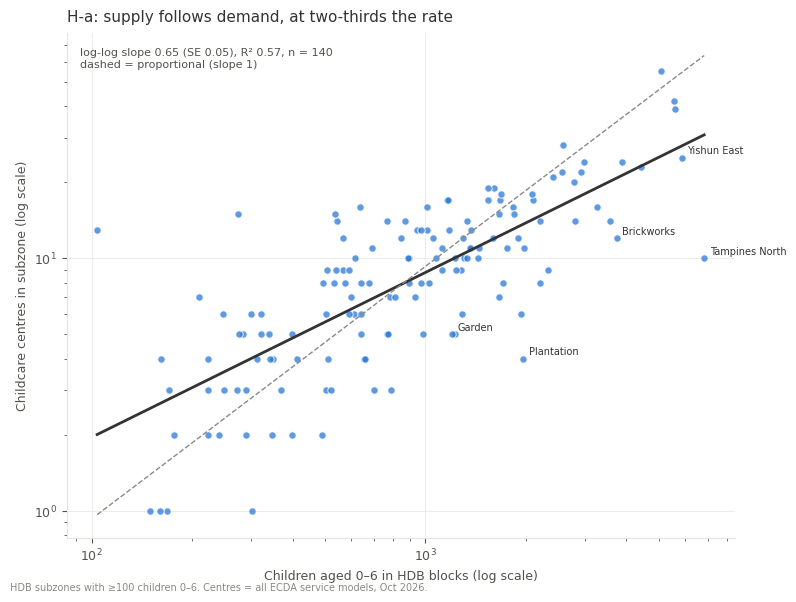

In [5]:
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(subzones["children_0_6"], subzones["centres_n"], s=28, color=BLUE, alpha=0.75, edgecolor="white", linewidth=0.8)
xs = np.linspace(x.min(), x.max(), 50)
ax.plot(np.exp(xs), np.exp(ols.params.iloc[0] + slope * xs), color=INK, lw=2)                   # fitted line
ax.plot(np.exp(xs), np.exp(xs) * np.exp(y.mean() - x.mean()), color=INK3, lw=1, ls="--")        # slope 1 reference
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Children aged 0–6 in HDB blocks (log scale)")
ax.set_ylabel("Childcare centres in subzone (log scale)")
ax.set_title("H-a: supply follows demand, at two-thirds the rate", loc="left", fontsize=11, pad=8)
ax.text(0.02, 0.97, f"log-log slope {slope:.2f} (SE {slope_se:.2f}), R² {ols.rsquared:.2f}, n = {len(subzones)}\n"
        "dashed = proportional (slope 1)", transform=ax.transAxes, va="top", fontsize=8, color=INK2)
for name in LABELLED:
    row = subzones[subzones["SUBZONE_N"] == name]
    if len(row):
        row = row.iloc[0]
        ax.annotate(name.title(), (row["children_0_6"], row["centres_n"]), fontsize=7, color=INK, xytext=(4, 3), textcoords="offset points")
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
ax.grid(color=GRID, lw=0.5)
ax.set_axisbelow(True)
fig.text(0.01, 0.01, "HDB subzones with ≥100 children 0–6. Centres = all ECDA service models, Oct 2026.", fontsize=7, color=INK3)
fig.tight_layout()
fig.savefig(FIG / "ha_centres_vs_children.png", dpi=170)
plt.show()

## 5. Best- and worst-served subzones by centres per 1,000 children

The bottom of this table is where stage 3 looks for weak links; the top shows that the ratio is
also inflated in small, central or mature subzones with few children and a few centres.

In [6]:
cols = ["SUBZONE_N", "PLN_AREA_N", "children_0_6", "centres_n", "centres_per_1000", "pressure_base"]
ranked = subzones.sort_values("centres_per_1000")[cols].rename(columns={"pressure_base": "children_per_reachable_centre"})
pd.set_option("display.width", 160)
print("lowest 10 (fewest centres per 1,000 children 0-6):")
print(ranked.head(10).round(1).to_string(index=False))
print("\nhighest 10:")
print(ranked.tail(10).iloc[::-1].round(1).to_string(index=False))
print("\nplanning areas of the 20 lowest-ratio subzones:")
print(ranked.head(20)["PLN_AREA_N"].value_counts().to_string())

lowest 10 (fewest centres per 1,000 children 0-6):
     SUBZONE_N  PLN_AREA_N  children_0_6  centres_n  centres_per_1000  children_per_reachable_centre
TAMPINES NORTH    TAMPINES        6838.4         10               1.5                          595.8
    PLANTATION      TENGAH        1960.0          4               2.0                          344.5
      BIDADARI   TOA PAYOH        1930.0          6               3.1                          195.3
    BRICKWORKS BUKIT BATOK        3740.8         12               3.2                          221.8
       REDHILL BUKIT MERAH         301.9          1               3.3                           83.1
WOODLANDS WEST   WOODLANDS        2205.8          8               3.6                          240.7
     BOON TECK   TOA PAYOH         789.1          3               3.8                          136.6
SEMBAWANG EAST   SEMBAWANG        2336.2          9               3.9                          246.4
       MATILDA     PUNGGOL        3565.3

In [7]:
print(f"wrote {(FIG / 'ha_centres_vs_children.png').relative_to(ROOT)}  (n = {len(subzones)} subzones)")

wrote figures/ha_centres_vs_children.png  (n = 140 subzones)
